# Task 16 - headcount forecast with uncertainty
Walkthrough of the pipeline in `src/cortexhr_task16`. Re-run with `python scripts/build_notebook.py`.

In [1]:
import sys, warnings; sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
from cortexhr_task16 import forecasting, exploratory_analysis as ea, config
res = forecasting.run(write=False)
print('selected model:', res['model'], '| trained through', res['trained_through'])

selected model: drift_events | trained through 2026-09


## 1. Data quality and EDA

In [2]:
print(res['quality'])
eda = ea.analyse(res['hist'], res['events'])
display(eda['annual'].round(1)); display(eda['by_month'].round(2)); display(eda['unusual'])

{'rows': 972, 'series': 12, 'first_month': '2020-01', 'last_month': '2026-09', 'n_months': 81, 'missing_values': 0, 'duplicate_keys': 0, 'missing_months': {}, 'flow_identity_violations': 0, 'start_end_continuity_violations': 0, 'departments_sum_equals_company': True}


,year_end_headcount,net_change_in_year,growth_pct,months_in_data
month,,,,
2020,172.0,NaN,NaN,12
2021,203.0,31.0,18.0,12
2022,270.0,67.0,33.0,12
2023,336.0,66.0,24.4,12
2024,378.0,42.0,12.5,12
2025,398.0,20.0,5.3,12
2026,441.0,43.0,10.8,9


,mean_net_change,sd_net_change,mean_hires,mean_exits,n_years
month,,,,,
1,6.00,1.90,9.00,3.71,6
2,3.71,5.91,7.43,3.71,7
3,1.29,4.75,5.57,4.29,7
4,1.00,3.32,4.86,3.86,7
5,-0.57,2.64,4.71,5.29,7
6,6.14,4.38,10.29,4.14,7
7,5.71,5.50,9.14,3.43,7
8,4.29,1.70,7.71,3.43,7
9,5.71,5.65,8.57,2.86,7


,month,net_change,modified_z,hires,exits,event_window
0,2023-07-01,14.0,3.70975,16,2,"EV-04, EV-05"
1,2026-09-01,14.0,3.70975,17,3,


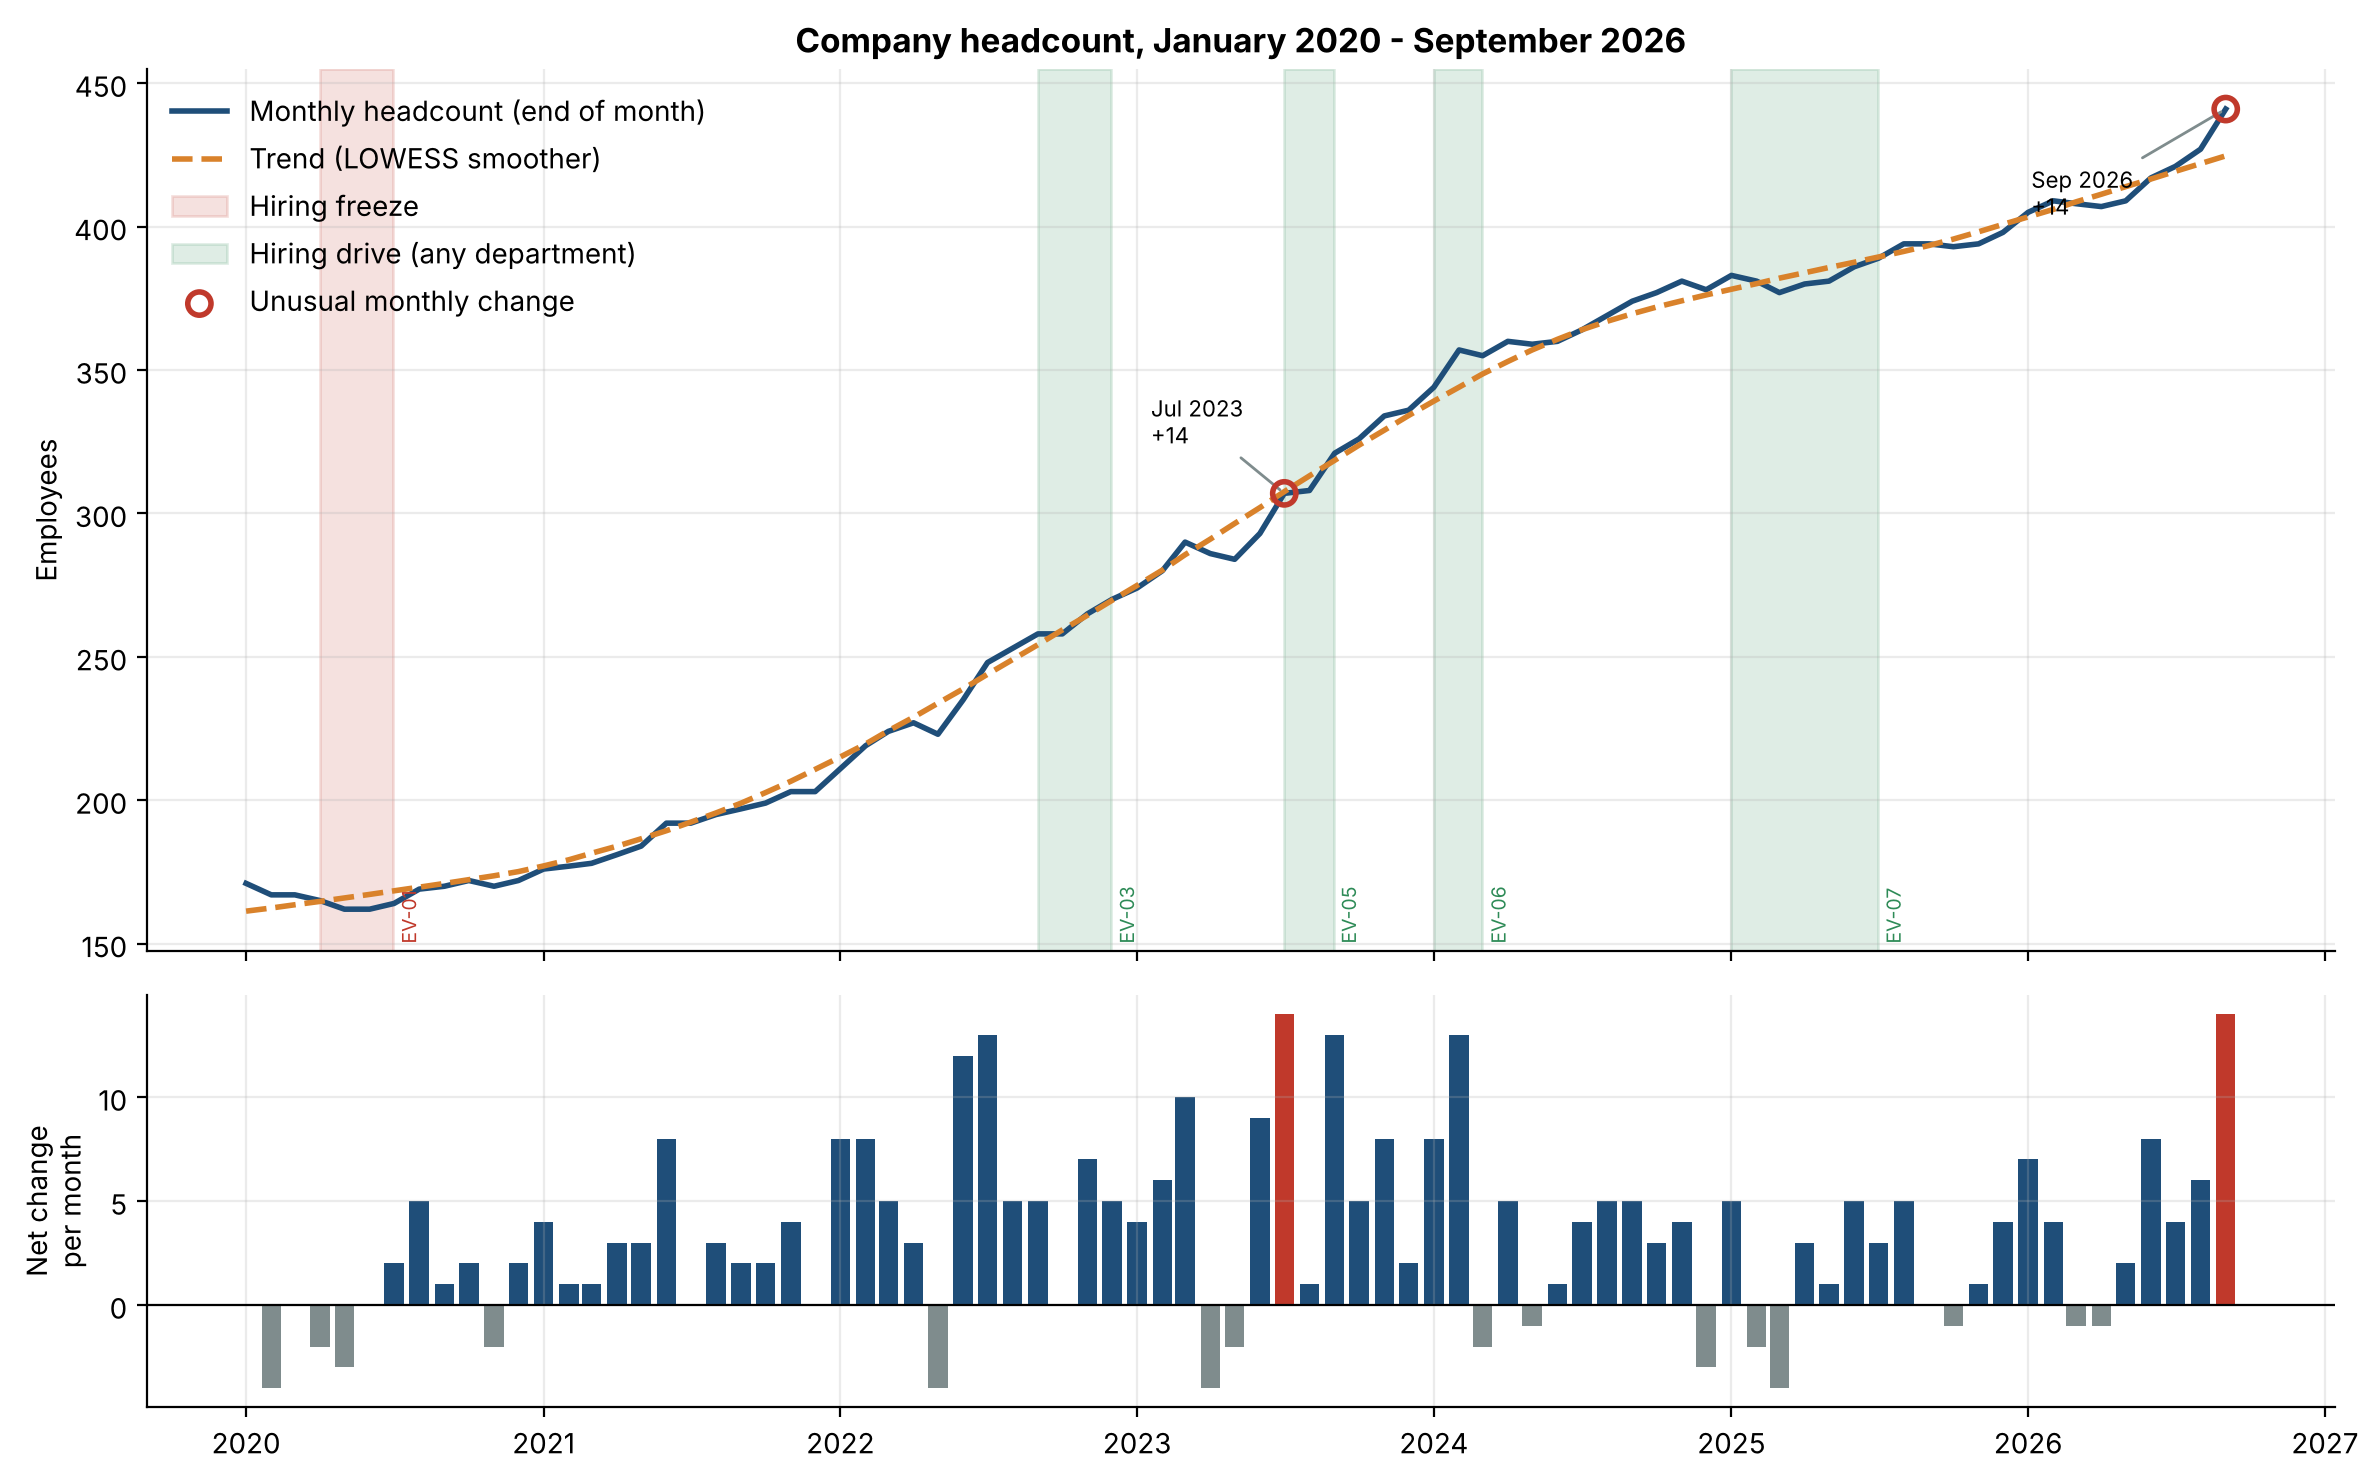

In [3]:
display(Image(str(config.CHARTS / 'historical_headcount.png')))

## 2. Model selection (cross-validation inside training data only)

In [4]:
display(res['cv_final'].round(3))

,model,label,complexity,cv_mae,cv_coverage_80,n_origins,failed_fits
0,drift_events,Drift + event dummies (OLS on monthly change),1,5.978,0.821,14,0
1,ets_damped,"ETS(A,Ad,N) damped trend",2,6.223,0.845,14,0
2,drift_events_fourier,Drift + event dummies + 2 seasonal harmonics,3,6.257,0.833,14,0
3,ets_holt_winters,"ETS(A,Ad,A) damped trend + additive seasonality",4,6.738,0.738,14,0
4,sarima,"SARIMA(0,1,1)(0,1,0)12",5,8.251,0.810,14,0
5,seasonal_baseline,Seasonal baseline (reference only),0,13.958,NaN,14,0


## 3. Six-month hold-out backtest

In [5]:
results, metrics = forecasting.backtest_tables(res)
display(metrics[metrics.department_id=='ALL'].round(2)); display(results[results.department_id=='ALL'].round(1))

,metric,department_id,model,method,MAE,RMSE,MAPE_pct,WAPE_pct,bias,n,coverage_80_pct,inside_80,mean_width_80
0,headcount_end,ALL,Seasonal Baseline,seasonal naive + annual trend,10.67,12.55,2.50,2.54,-10.67,6,100.00,6,50.03
1,headcount_end,ALL,Advanced Model,Drift + event dummies (OLS on monthly change),4.52,6.40,1.06,1.08,-1.11,6,100.00,6,20.04
22,attrition_rate_monthly_pct,ALL,Rate: selected,mean of the last 24 months,0.39,0.46,56.46,38.83,0.28,6,83.33,5,1.62
23,exits_count,ALL,Exits: selected,mean of the last 24 months,1.65,1.93,57.06,39.58,1.20,6,83.33,5,6.73
24,attrition_rate_monthly_pct,ALL,Rate: reference (sample method),same-month average of the last 3 years,0.53,0.61,72.48,53.00,0.35,6,83.33,5,2.03
25,exits_count,ALL,Exits: reference (sample method),same-month average of the last 3 years,2.24,2.55,73.32,53.71,1.46,6,83.33,5,8.43


,department_id,month,actual,baseline_forecast,baseline_lower_80,baseline_upper_80,advanced_forecast,advanced_lower_80,advanced_upper_80,baseline_abs_error,advanced_abs_error
0,ALL,2026-04-01,407.0,402.3,380.8,419.7,411.2,405.8,416.6,4.7,4.2
1,ALL,2026-05-01,409.0,403.3,379.8,423.3,414.4,406.7,422.1,5.7,5.4
2,ALL,2026-06-01,417.0,408.3,383.0,430.4,417.6,408.1,427.2,8.7,0.6
3,ALL,2026-07-01,421.0,411.3,383.3,435.3,420.8,409.7,431.9,9.7,0.2
4,ALL,2026-08-01,427.0,416.3,385.4,441.9,424.0,411.5,436.6,10.7,3.0
5,ALL,2026-09-01,441.0,416.3,381.5,443.4,427.2,413.4,441.1,24.7,13.8


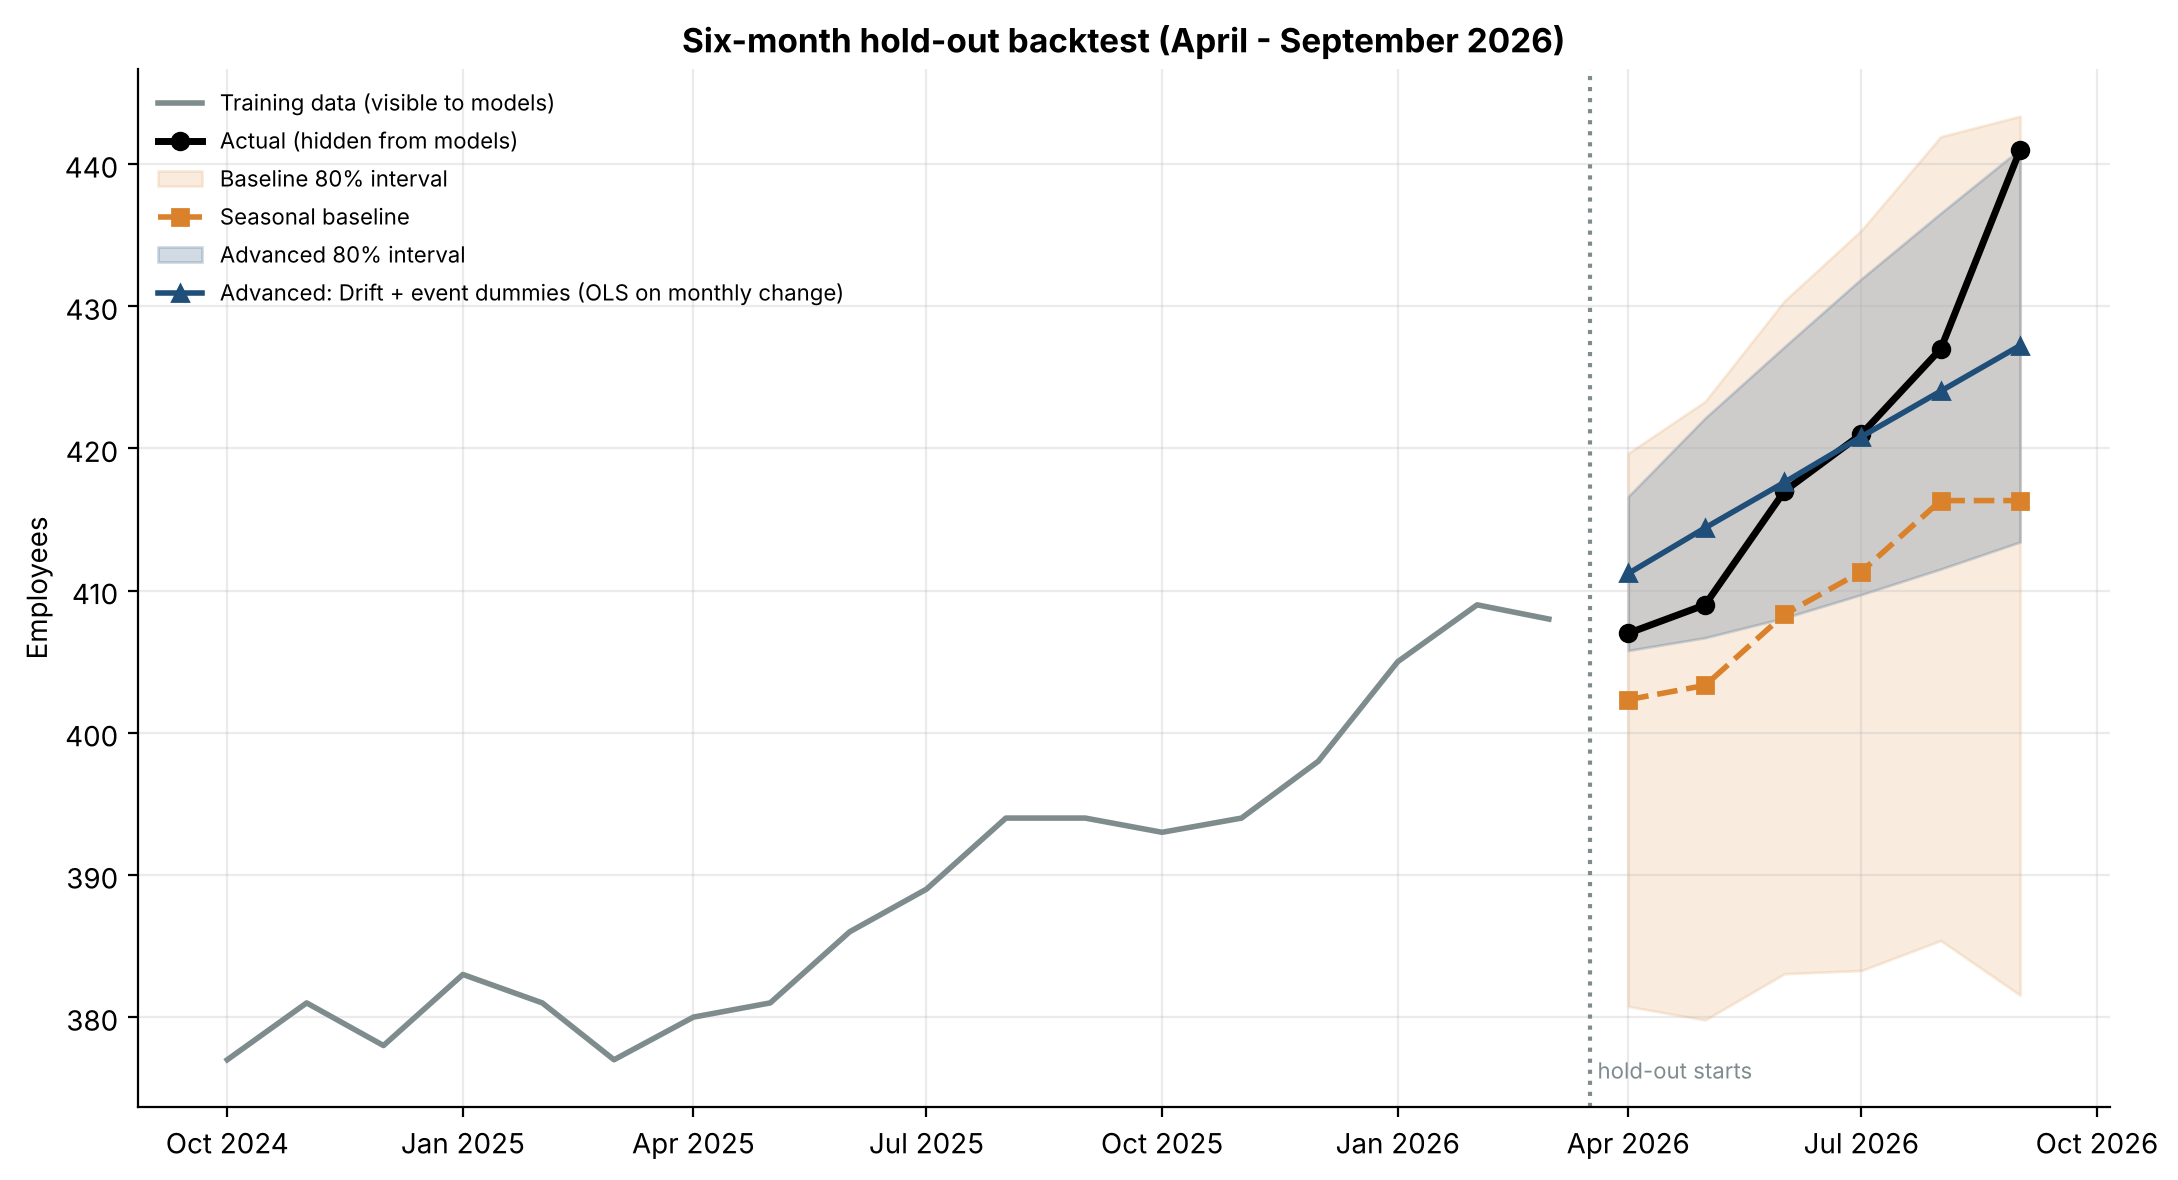

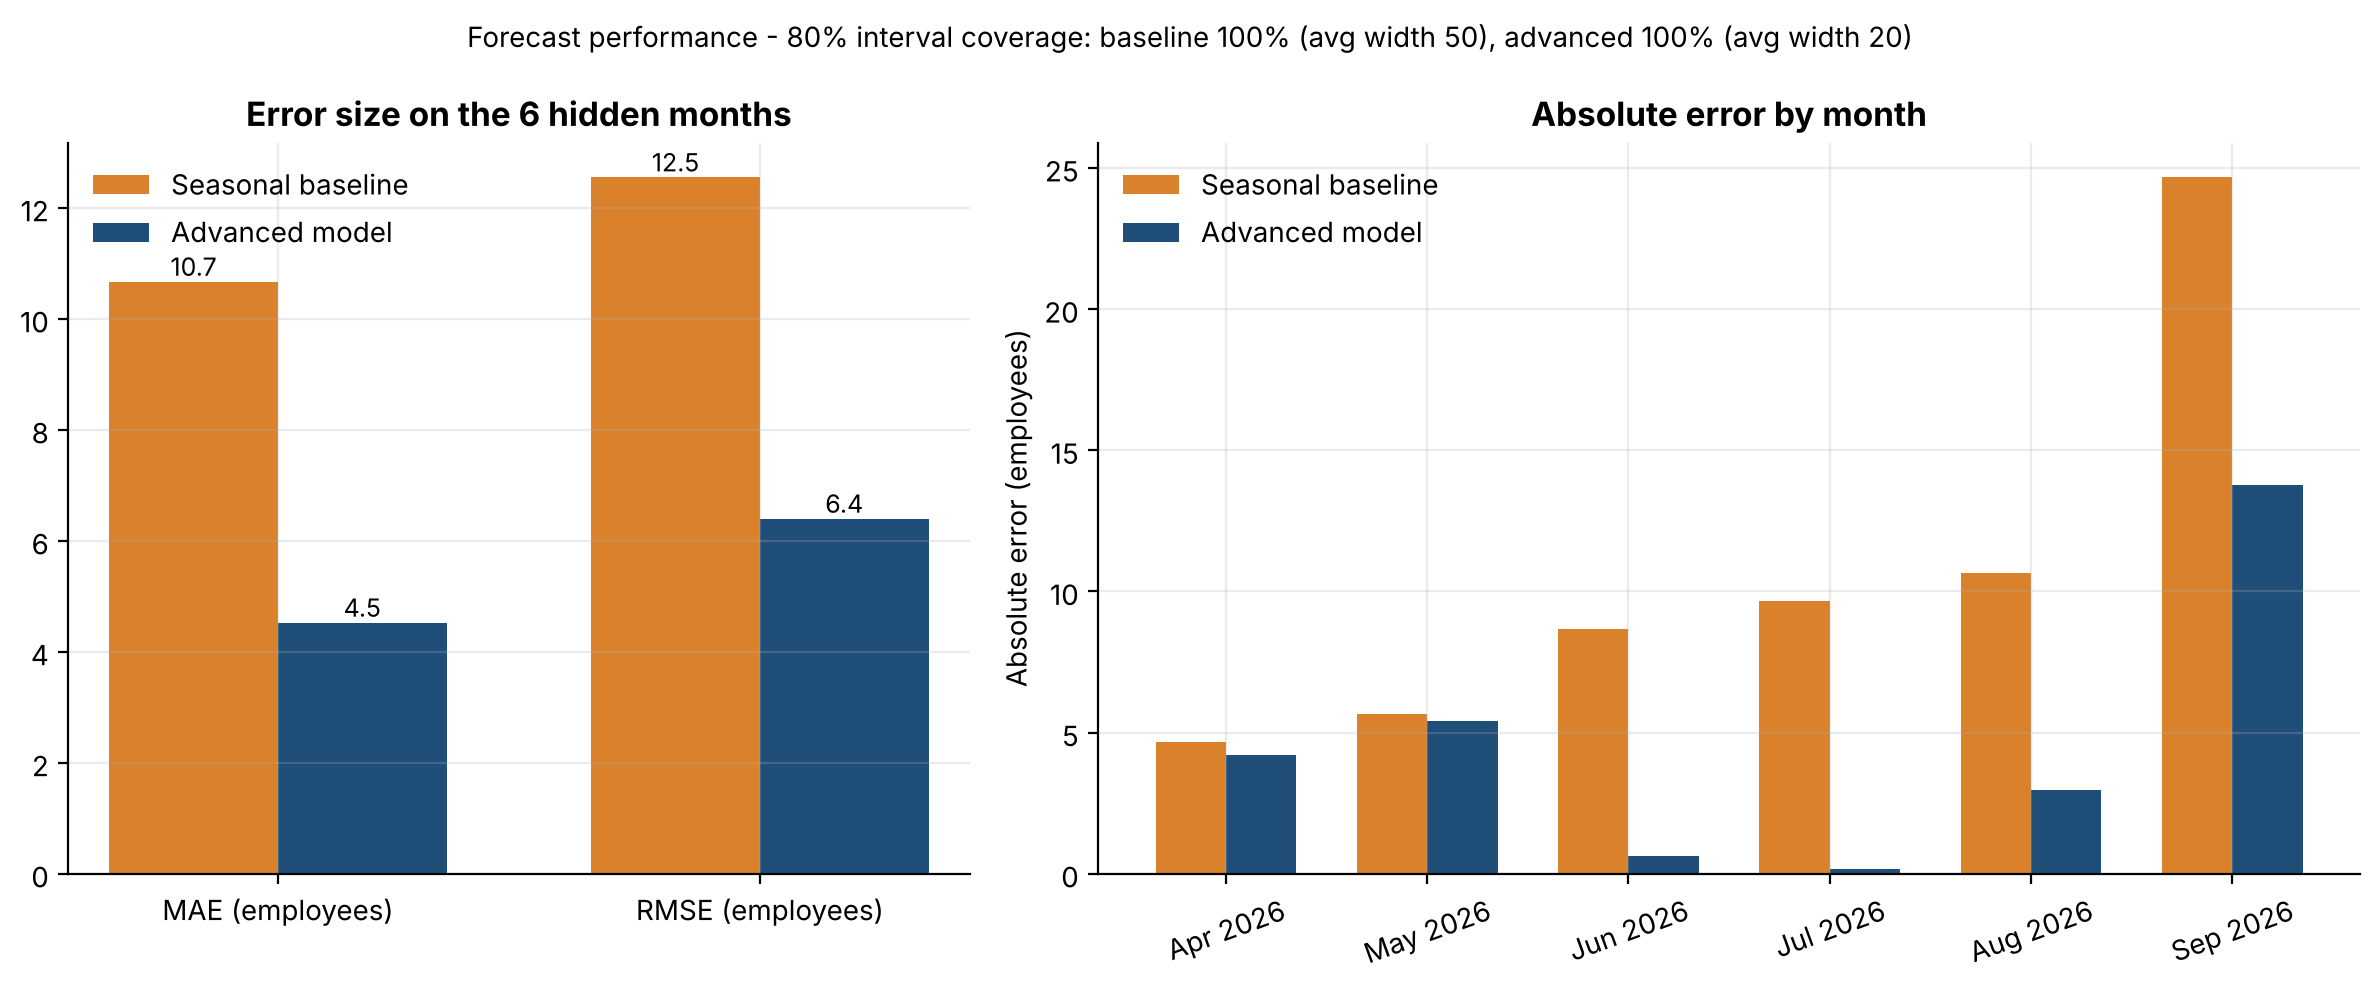

In [6]:
display(Image(str(config.CHARTS / 'backtest_comparison.png'))); display(Image(str(config.CHARTS / 'model_performance.png')))

## 4. Forecast Oct 2026 - Mar 2027 and reliability

In [7]:
display(res['headcount_fc']['ALL'].round(1)); display(res['exits_fc'].round(2)); display(res['reliability']['table'].round(2))

,mean,lower,upper,event_adjustment
2026-10-01,444.4,438.9,450.0,0.0
2026-11-01,447.8,440.0,455.7,0.0
2026-12-01,451.3,441.5,461.0,0.0
2027-01-01,454.7,443.4,466.0,0.0
2027-02-01,458.1,445.4,470.8,0.0
2027-03-01,461.5,447.5,475.6,0.0


,opening_headcount,expected_attrition_rate_pct,expected_exits,lower_80,upper_80,expected_net_change,implied_hires_needed
2026-10-01,441.00,1.22,5.38,1.88,8.64,3.42,8.80
2026-11-01,444.42,1.22,5.42,1.89,8.71,3.42,8.84
2026-12-01,447.84,1.22,5.46,1.91,8.77,3.42,8.88
2027-01-01,451.27,1.22,5.50,1.92,8.84,3.42,8.93
2027-02-01,454.69,1.22,5.55,1.94,8.91,3.42,8.97
2027-03-01,458.11,1.22,5.59,1.95,8.98,3.42,9.01


,month,step,forecast,width_80,relative_width_pct,calendar_month_change_sd,cv_mae_at_step,future_event
0,2026-10-01,1,444.42,11.06,2.49,2.14,3.00,False
1,2026-11-01,2,447.84,15.76,3.52,3.72,5.30,False
2,2026-12-01,3,451.27,19.44,4.31,2.88,6.10,False
3,2027-01-01,4,454.69,22.62,4.97,1.90,5.93,False
4,2027-02-01,5,458.11,25.47,5.56,5.91,7.15,False
5,2027-03-01,6,461.53,28.11,6.09,4.75,8.38,False


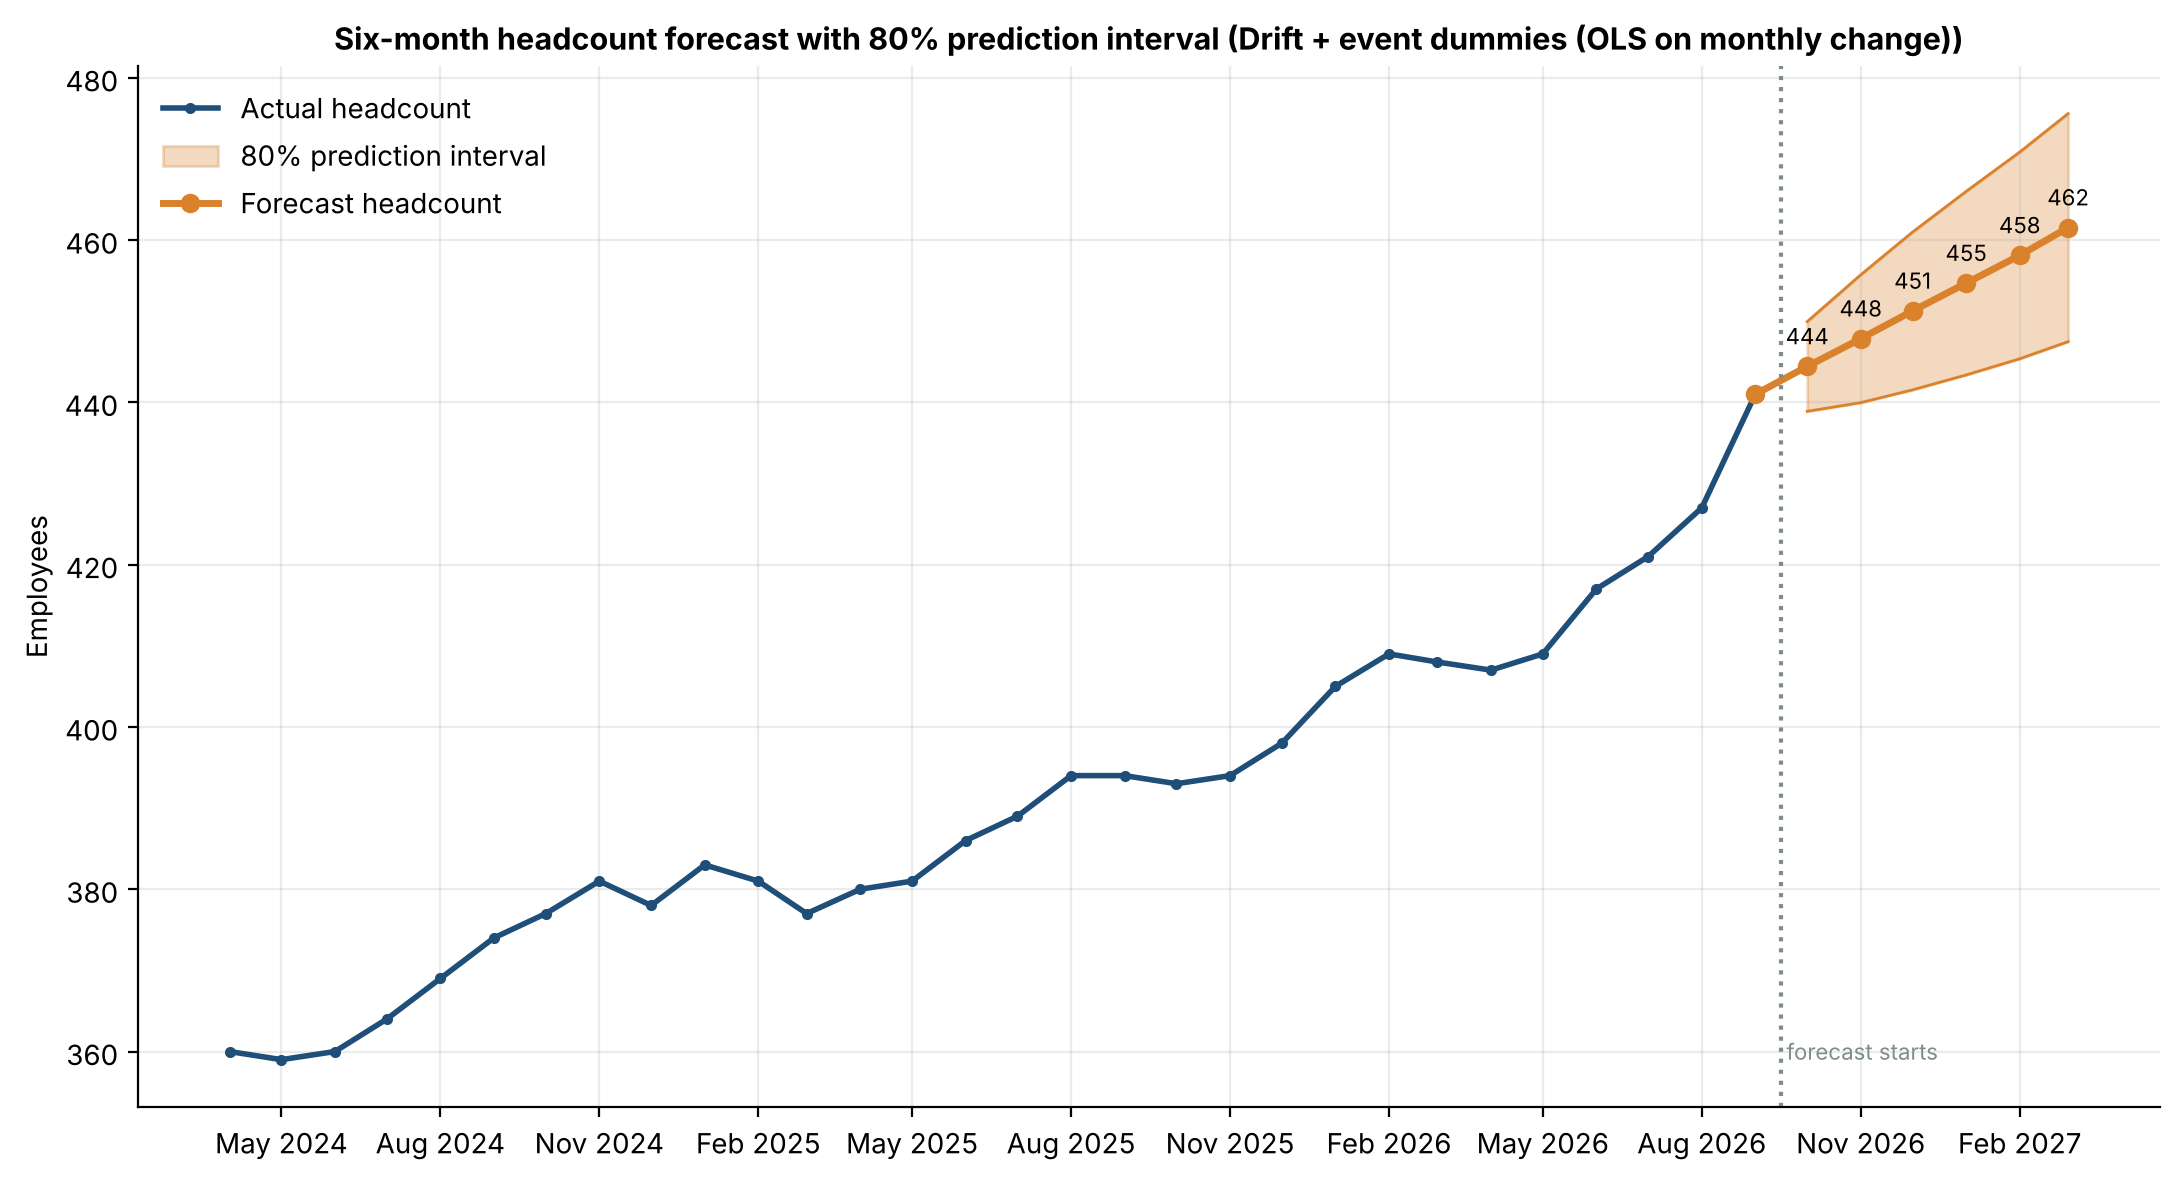

In [8]:
display(Image(str(config.CHARTS / 'six_month_forecast.png')))